# 02 Baselines

Target: on a legal ball, does the bowler take the striker's wicket? (See `01_eda`.)
Train on 2008 to 2023, test on 2024 and 2025. The test seasons are not looked at until
the model and its settings are fixed by cross-validation on the training seasons.

Two baselines:

1. the overall training rate (and, as a step up, the rate per phase);
2. an L2-regularised logistic regression on one-hot batter, bowler and phase (and
   venue, if cross-validation says it helps). Players not seen in training get a zero
   coefficient, so they are treated as average.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

balls = pd.read_parquet(ROOT / "data" / "legal_balls.parquet")
TEST_SEASONS = [2024, 2025]
train = balls[~balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
test = balls[balls.season.isin(TEST_SEASONS)].reset_index(drop=True)
print(f"train {len(train):,} balls ({train.season.min()}-{train.season.max()}), "
      f"test {len(test):,} balls ({test.season.min()}-{test.season.max()})")

train 234,995 balls (2008-2023), test 32,806 balls (2024-2025)


In [2]:
def scores(y, p):
    return {"log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p)}


def logistic(features, C):
    enc = ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore"), features)], sparse_threshold=1.0
    )
    return make_pipeline(enc, LogisticRegression(C=C, max_iter=2000))

## Time-aware cross-validation

Expanding window: to validate on season *s*, fit on every training season before *s*.
Five folds, validating on 2019 to 2023. No ball from the future is used to predict the
past.

In [3]:
FEATURES = {
    "batter+bowler+phase": ["batter_id", "bowler_id", "phase"],
    "batter+bowler+phase+venue": ["batter_id", "bowler_id", "phase", "venue_clean"],
}
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
VAL_SEASONS = [2019, 2020, 2021, 2022, 2023]

rows = []
for s in VAL_SEASONS:
    tr, va = train[train.season < s], train[train.season == s]
    rows.append({"features": "overall rate", "C": np.nan, "season": s,
                 **scores(va.wicket, np.full(len(va), tr.wicket.mean()))})
    for name, feats in FEATURES.items():
        for C in C_GRID:
            m = logistic(feats, C).fit(tr[feats], tr.wicket)
            rows.append({"features": name, "C": C, "season": s,
                         **scores(va.wicket, m.predict_proba(va[feats])[:, 1])})
cv = pd.DataFrame(rows)
cv_mean = cv.groupby(["features", "C"], dropna=False)[["log_loss", "brier"]].mean()
cv_mean.round(5)

log_loss    brier
features                  C                       
batter+bowler+phase       0.003   0.18888  0.04511
                          0.010   0.18865  0.04508
                          0.030   0.18856  0.04507
                          0.100   0.18879  0.04510
                          0.300   0.18920  0.04515
                          1.000   0.18983  0.04523
batter+bowler+phase+venue 0.003   0.18891  0.04511
                          0.010   0.18869  0.04509
                          0.030   0.18863  0.04508
                          0.100   0.18897  0.04512
                          0.300   0.18940  0.04517
                          1.000   0.19005  0.04527
overall rate              NaN     0.19152  0.04537

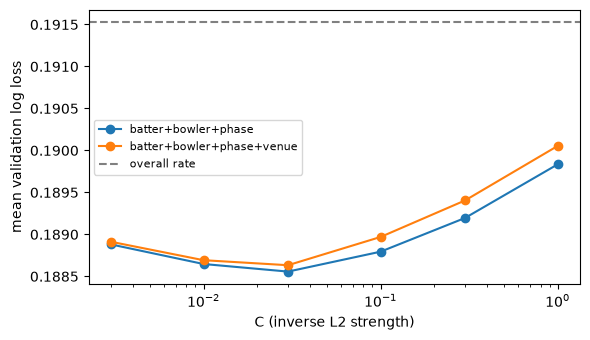

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in FEATURES:
    t = cv_mean.loc[name]
    ax.plot(t.index, t.log_loss, "o-", label=name)
ax.axhline(cv.loc[cv.features == "overall rate", "log_loss"].mean(), color="grey", ls="--",
           label="overall rate")
ax.set_xscale("log")
ax.set_xlabel("C (inverse L2 strength)")
ax.set_ylabel("mean validation log loss")
ax.legend(fontsize=8)
fig.tight_layout()

Pick the feature set and C with the lowest mean validation log loss. The differences
between settings are small next to the fold-to-fold spread, so I also look at how many
folds each choice wins.

In [5]:
best_name, best_C = cv_mean.drop(index="overall rate", level=0).log_loss.idxmin()
print("chosen:", best_name, "C =", best_C)
per_fold = cv[cv.features != "overall rate"].pivot_table(
    index="season", columns=["features", "C"], values="log_loss"
)
print("fold-by-fold, best C per feature set:")
best_per_set = {n: cv_mean.loc[n].log_loss.idxmin() for n in FEATURES}
pd.DataFrame({n: per_fold[(n, c)] for n, c in best_per_set.items()}).round(5)

chosen: batter+bowler+phase C = 0.03
fold-by-fold, best C per feature set:


,batter+bowler+phase,batter+bowler+phase+venue
season,,
2019,0.18269,0.18261
2020,0.17967,0.18012
2021,0.18990,0.18996
2022,0.19470,0.19464
2023,0.19583,0.19584


## Fit on all training seasons and score the test seasons

In [6]:
feats = FEATURES[best_name]
model = logistic(feats, best_C).fit(train[feats], train.wicket)

phase_rate = train.groupby("phase").wicket.mean()
preds = pd.DataFrame(
    {
        "overall rate": np.full(len(test), train.wicket.mean()),
        "phase rate": test.phase.map(phase_rate).to_numpy(),
        "logistic L2": model.predict_proba(test[feats])[:, 1],
    }
)
table = pd.DataFrame({k: scores(test.wicket, p) for k, p in preds.items()}).T
table["mean predicted"] = preds.mean()
table["observed rate"] = test.wicket.mean()
table.round(5)

,log_loss,brier,mean predicted,observed rate
overall rate,0.19973,0.04784,0.04653,0.05036
phase rate,0.19805,0.04766,0.04633,0.05036
logistic L2,0.19726,0.04759,0.04854,0.05036


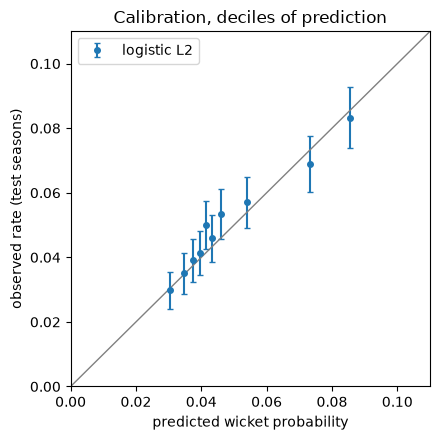

In [7]:
def calibration_plot(ax, y, p, label, n_bins=10):
    q = pd.qcut(p, n_bins, duplicates="drop")
    g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True)
    obs, pred, n = g.y.mean(), g.p.mean(), g.y.size()
    se = np.sqrt(obs * (1 - obs) / n)
    ax.errorbar(pred, obs, yerr=1.96 * se, fmt="o", ms=4, capsize=2, label=label)


fig, ax = plt.subplots(figsize=(4.5, 4.5))
calibration_plot(ax, test.wicket, preds["logistic L2"], "logistic L2")
lim = [0, 0.11]
ax.plot(lim, lim, color="grey", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="predicted wicket probability",
       ylabel="observed rate (test seasons)", title="Calibration, deciles of prediction")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "calibration_baseline.png", dpi=120)

Save the chosen settings, the test metrics and the per-ball test predictions so the
hierarchical model in `03` is scored on exactly the same balls.

In [8]:
table.to_csv(RESULTS / "baseline_test_metrics.csv")
cv.to_csv(RESULTS / "baseline_cv.csv", index=False)
with open(RESULTS / "baseline_settings.json", "w") as f:
    json.dump({"features": feats, "C": best_C, "train_seasons": [int(train.season.min()),
               int(train.season.max())], "test_seasons": TEST_SEASONS}, f, indent=2)
out = test[["match_id", "season", "batter_id", "bowler_id", "phase", "wicket"]].copy()
out["p_logistic"] = preds["logistic L2"].to_numpy()
out["p_overall"] = preds["overall rate"].to_numpy()
out.to_parquet(ROOT / "data" / "test_preds_baseline.parquet", index=False)
print("saved results/baseline_*.{csv,json} and data/test_preds_baseline.parquet")

saved results/baseline_*.{csv,json} and data/test_preds_baseline.parquet


## What this shows

* Venue does not earn its place. Adding it never lowers the best mean validation log
  loss, and it wins only two of the five folds. The baseline uses batter, bowler and
  phase, with C = 0.03.
* On 2024-25 the logistic model beats the overall rate and the phase rates on both log
  loss and Brier score, but the gains are small in absolute terms: wickets are rare and
  most of the uncertainty about any one ball cannot be removed.
* Every model predicts fewer wickets than happened. Wicket rates rose after 2021 and the
  test seasons sit above anything in training. The hierarchical model in `03` uses the
  same training data, so it will share this offset; it is a property of the split, not
  of either model.